# BigMart Sales Prediction & Comprehensive Exploratory Data Analysis (EDA)

1. **Objective**: Build a predictive machine learning model to forecast product sales (`Item_Outlet_Sales`) across different BigMart store outlets in various cities.
2. **Dataset**: 8,523 training records across 1,559 products and 10 outlets, with 5,681 test records to be predicted.
3. **Comprehensive EDA**: Implements complete data inspection, univariate and multivariate visualizations, correlation matrix heatmap, multi-method outlier detection (IQR, 3-sigma, 99th percentile), and before/after transformation studies inspired by advanced statistical EDA workflows.
4. **Modeling**: Employs scikit-learn Pipelines with median numerical imputation, mode categorical imputation, One-Hot Encoding, Random Forest Regressor, and Gradient Boosting Regressor evaluated using Root Mean Squared Error (RMSE).


In [1]:
import os
import warnings
warnings.filterwarnings('ignore')

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

try:
    from IPython.display import display
except ImportError:
    display = print

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_squared_error

# Set visual style for plots
sns.set_theme(style='whitegrid')
plt.rcParams['figure.titlesize'] = 14
plt.rcParams['axes.labelsize'] = 11

print('Libraries successfully imported.')


Libraries successfully imported.


## 2. Loading Datasets




In [3]:
from google.colab import files
uploaded = files.upload()

train = pd.read_csv('train.csv')
test = pd.read_csv('test.csv')

display(train.head())
display(test.head())

Saving train.csv to train.csv
Saving test.csv to test.csv


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700
3,FDX07,19.20,Regular,0.000000,Fruits and Vegetables,182.0950,OUT010,1998,NaN,Tier 3,Grocery Store,732.3800
4,NCD19,8.93,Low Fat,0.000000,Household,53.8614,OUT013,1987,High,Tier 3,Supermarket Type1,994.7052


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type
0,FDW58,20.750,Low Fat,0.007565,Snack Foods,107.8622,OUT049,1999,Medium,Tier 1,Supermarket Type1
1,FDW14,8.300,reg,0.038428,Dairy,87.3198,OUT017,2007,NaN,Tier 2,Supermarket Type1
2,NCN55,14.600,Low Fat,0.099575,Others,241.7538,OUT010,1998,NaN,Tier 3,Grocery Store
3,FDQ58,7.315,Low Fat,0.015388,Snack Foods,155.0340,OUT017,2007,NaN,Tier 2,Supermarket Type1
4,FDY38,NaN,Regular,0.118599,Dairy,234.2300,OUT027,1985,Medium,Tier 3,Supermarket Type3


## 3. Initial Data Inspection

1. Overview of column names, non-null counts, and data types via `info()`.
2. Summary statistics of numerical columns via `describe()`.
3. Analysis of unique value counts across all attributes.
4. Normalized percentage distribution of key categorical features.


In [4]:
print('--- Dataset Info ---')
print(train.info())

print('\n--- Number of Unique Values per Column ---')
unique_counts = pd.DataFrame({
    'Data Type': train.dtypes,
    'Unique Values': train.nunique(),
    'Sample Values': [train[col].dropna().unique()[:3].tolist() for col in train.columns]
})
display(unique_counts)

print('\n--- Numerical Descriptive Statistics ---')
display(train.describe().round(2))

print('\n--- Categorical Feature Distributions (Percentages) ---')
for col in ['Item_Fat_Content', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type']:
    print(f'\nDistribution for {col}:')
    dist_df = pd.DataFrame({
        'Count': train[col].value_counts(dropna=False),
        'Percentage (%)': (train[col].value_counts(dropna=False, normalize=True) * 100).round(2)
    })
    display(dist_df)


--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8523 entries, 0 to 8522
Data columns (total 12 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Item_Identifier            8523 non-null   object 
 1   Item_Weight                7060 non-null   float64
 2   Item_Fat_Content           8523 non-null   object 
 3   Item_Visibility            8523 non-null   float64
 4   Item_Type                  8523 non-null   object 
 5   Item_MRP                   8523 non-null   float64
 6   Outlet_Identifier          8523 non-null   object 
 7   Outlet_Establishment_Year  8523 non-null   int64  
 8   Outlet_Size                6113 non-null   object 
 9   Outlet_Location_Type       8523 non-null   object 
 10  Outlet_Type                8523 non-null   object 
 11  Item_Outlet_Sales          8523 non-null   float64
dtypes: float64(4), int64(1), object(7)
memory usage: 799.2+ KB
None

--- Number of Uniq

,Data Type,Unique Values,Sample Values
Item_Identifier,object,1559,"[FDA15, DRC01, FDN15]"
Item_Weight,float64,415,"[9.3, 5.92, 17.5]"
Item_Fat_Content,object,5,"[Low Fat, Regular, low fat]"
Item_Visibility,float64,7880,"[0.016047301, 0.019278216, 0.016760075]"
Item_Type,object,16,"[Dairy, Soft Drinks, Meat]"
Item_MRP,float64,5938,"[249.8092, 48.2692, 141.618]"
Outlet_Identifier,object,10,"[OUT049, OUT018, OUT010]"
Outlet_Establishment_Year,int64,9,"[1999, 2009, 1998]"
Outlet_Size,object,3,"[Medium, High, Small]"
Outlet_Location_Type,object,3,"[Tier 1, Tier 3, Tier 2]"



--- Numerical Descriptive Statistics ---


,Item_Weight,Item_Visibility,Item_MRP,Outlet_Establishment_Year,Item_Outlet_Sales
count,7060.00,8523.00,8523.00,8523.00,8523.00
mean,12.86,0.07,140.99,1997.83,2181.29
std,4.64,0.05,62.28,8.37,1706.50
min,4.56,0.00,31.29,1985.00,33.29
25%,8.77,0.03,93.83,1987.00,834.25
50%,12.60,0.05,143.01,1999.00,1794.33
75%,16.85,0.09,185.64,2004.00,3101.30
max,21.35,0.33,266.89,2009.00,13086.96



--- Categorical Feature Distributions (Percentages) ---

Distribution for Item_Fat_Content:


...

,Count,Percentage (%)
Outlet_Size,,
Medium,2793,32.77
NaN,2410,28.28
Small,2388,28.02
High,932,10.94



Distribution for Outlet_Location_Type:


,Count,Percentage (%)
Outlet_Location_Type,,
Tier 3,3350,39.31
Tier 2,2785,32.68
Tier 1,2388,28.02



Distribution for Outlet_Type:


,Count,Percentage (%)
Outlet_Type,,
Supermarket Type1,5577,65.43
Grocery Store,1083,12.71
Supermarket Type3,935,10.97
Supermarket Type2,928,10.89


## 4. Missing-Value and Duplicate Analysis

1. Counts and percentage of missing values in each column for both train and test sets.
2. Duplicate record verification.
3. Observation: `Item_Weight` is missing in ~17.17% of training rows, while `Outlet_Size` is missing in ~28.28% of rows.


Duplicate rows in training set: 0
Missing Values Summary:


,Train Missing Count,Train Missing (%),Test Missing Count,Test Missing (%)
Item_Weight,1463,17.17,976.0,17.18
Outlet_Size,2410,28.28,1606.0,28.27


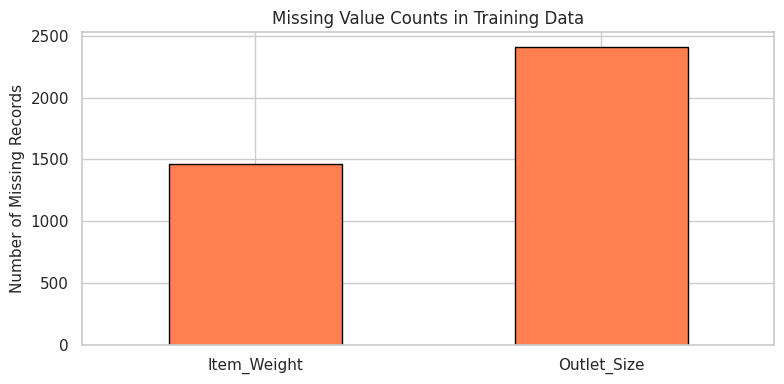

In [5]:
print('Duplicate rows in training set:', train.duplicated().sum())

missing_train = pd.DataFrame({
    'Train Missing Count': train.isnull().sum(),
    'Train Missing (%)': (train.isnull().sum() / len(train) * 100).round(2),
    'Test Missing Count': test.isnull().sum(),
    'Test Missing (%)': (test.isnull().sum() / len(test) * 100).round(2)
})
missing_train = missing_train[(missing_train['Train Missing Count'] > 0) | (missing_train['Test Missing Count'] > 0)]
print('Missing Values Summary:')
display(missing_train)

# Visualizing missing values
plt.figure(figsize=(8, 4))
train.isnull().sum()[train.isnull().sum() > 0].plot(kind='bar', color='coral', edgecolor='black')
plt.title('Missing Value Counts in Training Data')
plt.ylabel('Number of Missing Records')
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


## 5. Univariate Exploratory Data Analysis

1. Histograms for all numerical features to examine shape, spread, and modality.
2. Distribution plots with Kernel Density Estimation (KDE) curves for key variables.
3. Comprehensive boxplots for numerical attributes to evaluate dispersion and outliers.
4. Bar charts for categorical variable frequencies.
5. Skewness calculations to identify asymmetric distributions.


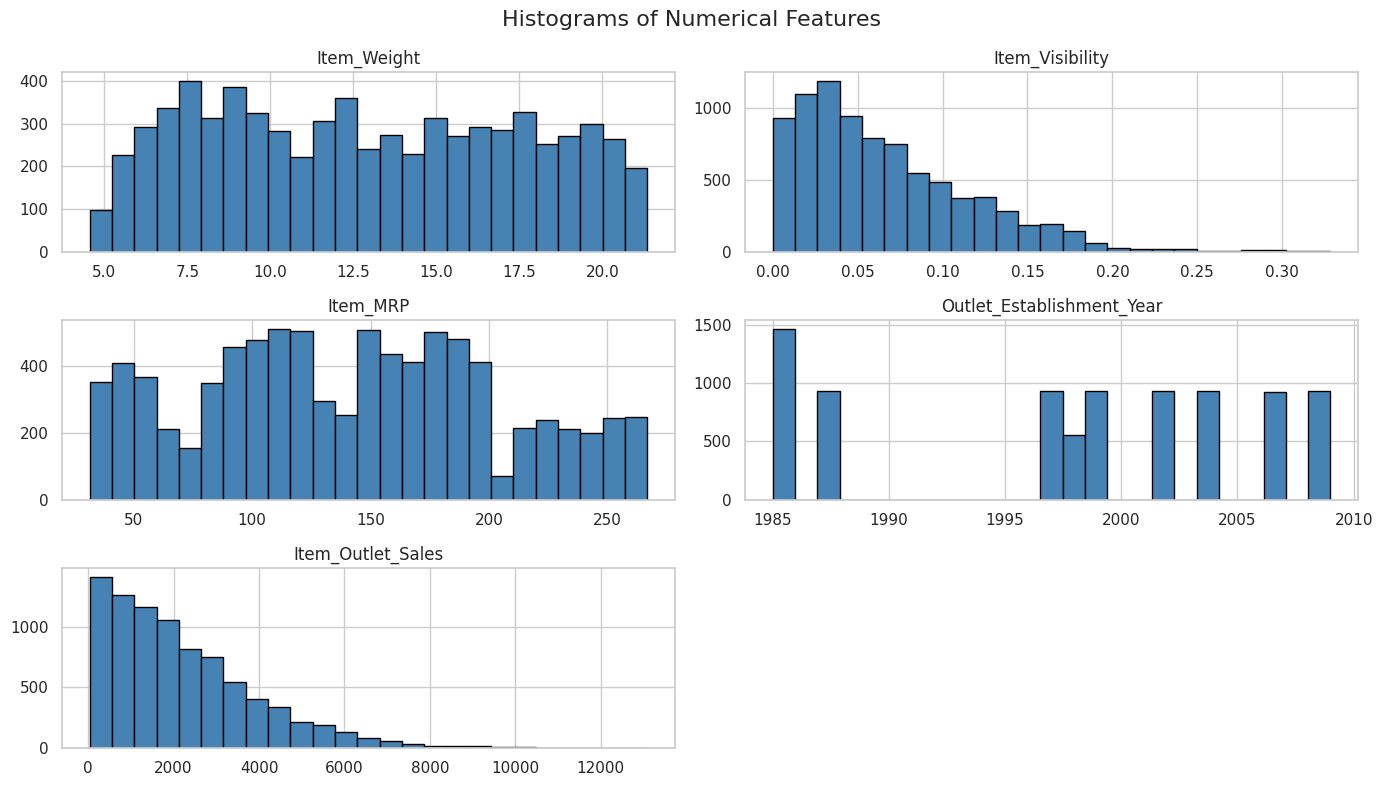

Skewness Analysis for Numerical Variables:


,Skewness,Interpretation
Item_Weight,0.082,Fairly symmetric
Item_Visibility,1.167,Highly positive skewed
Item_MRP,0.127,Fairly symmetric
Outlet_Establishment_Year,-0.397,Fairly symmetric
Item_Outlet_Sales,1.178,Highly positive skewed


In [6]:
# Select numeric columns
num_cols_eda = train.select_dtypes(include='number').columns.tolist()

# 5.1 Grid of histograms for all numerical features
train[num_cols_eda].hist(figsize=(14, 8), bins=25, edgecolor='black', color='steelblue')
plt.suptitle('Histograms of Numerical Features', fontsize=16)
plt.tight_layout()
plt.show()

# 5.2 Skewness analysis table
skewness_df = pd.DataFrame({
    'Skewness': train[num_cols_eda].skew().round(3),
    'Interpretation': train[num_cols_eda].skew().apply(
        lambda s: 'Highly positive skewed' if s > 1 else (
            'Moderately positive skewed' if s > 0.5 else (
                'Fairly symmetric' if s >= -0.5 else 'Negative skewed'
            )
        )
    )
})
print('Skewness Analysis for Numerical Variables:')
display(skewness_df)


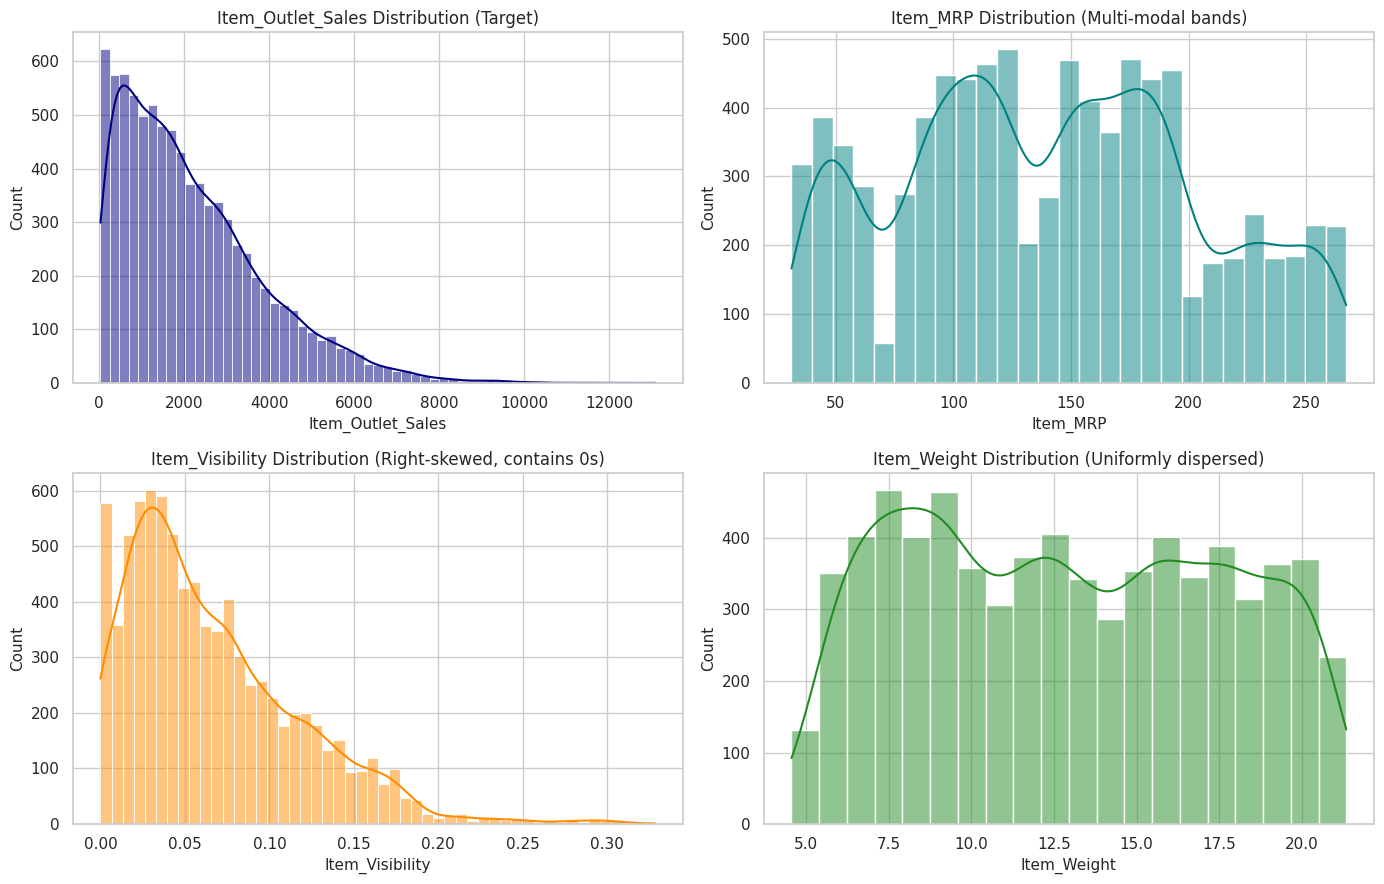

In [7]:
# 5.3 Detailed distribution plots with KDE curves for key predictors
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

sns.histplot(train['Item_Outlet_Sales'], kde=True, ax=axes[0, 0], color='navy')
axes[0, 0].set_title('Item_Outlet_Sales Distribution (Target)')

sns.histplot(train['Item_MRP'], kde=True, ax=axes[0, 1], color='teal')
axes[0, 1].set_title('Item_MRP Distribution (Multi-modal bands)')

sns.histplot(train['Item_Visibility'], kde=True, ax=axes[1, 0], color='darkorange')
axes[1, 0].set_title('Item_Visibility Distribution (Right-skewed, contains 0s)')

sns.histplot(train['Item_Weight'].dropna(), kde=True, ax=axes[1, 1], color='forestgreen')
axes[1, 1].set_title('Item_Weight Distribution (Uniformly dispersed)')

plt.tight_layout()
plt.show()


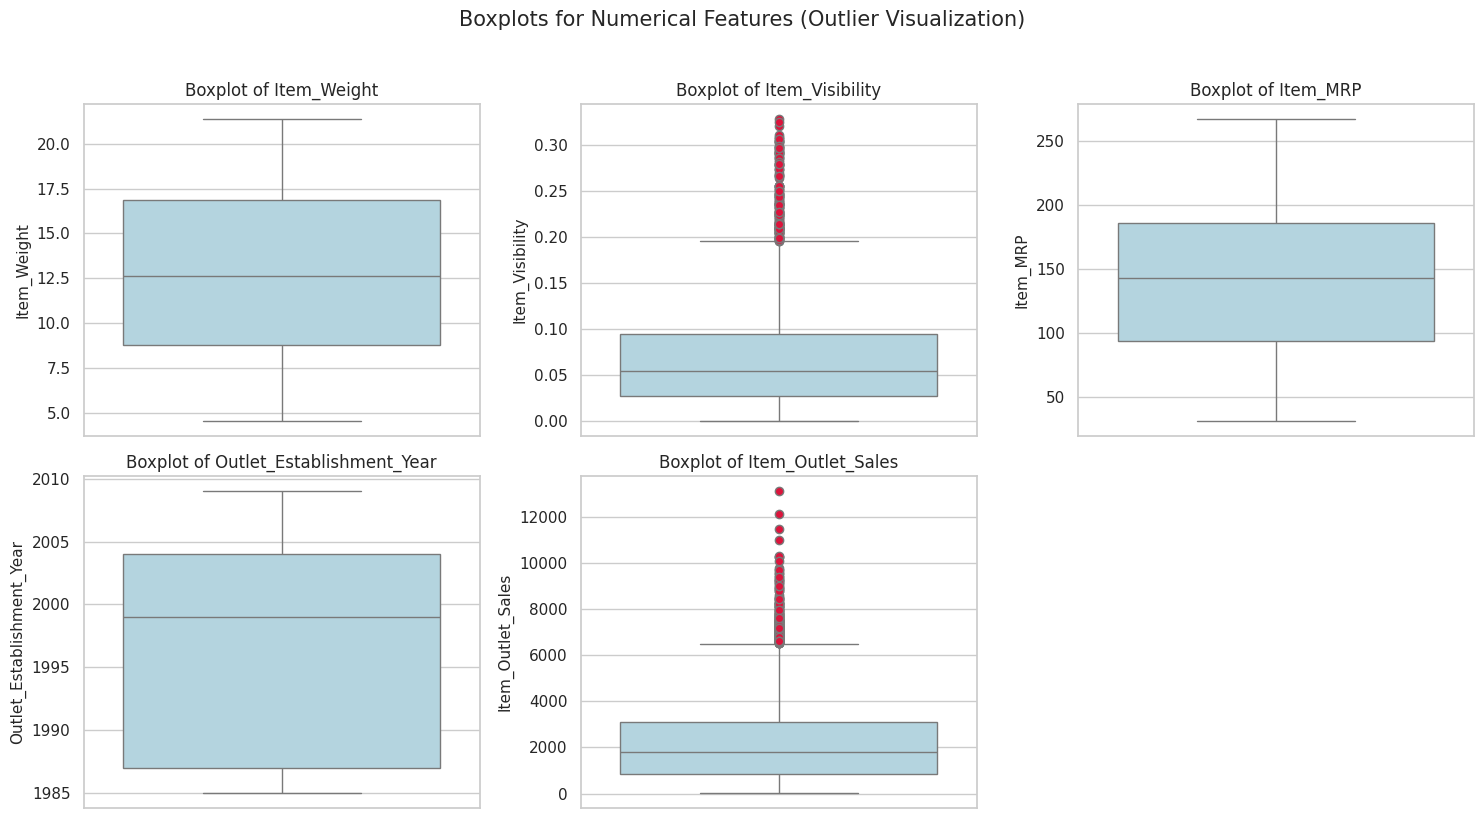

In [8]:
# 5.4 Boxplots for all numerical features
cols = 3
rows = (len(num_cols_eda) + cols - 1) // cols
fig, axes = plt.subplots(rows, cols, figsize=(15, rows * 4))
axes = axes.flatten()

for i, col in enumerate(num_cols_eda):
    sns.boxplot(y=train[col], ax=axes[i], color='lightblue', flierprops={'marker': 'o', 'markerfacecolor': 'crimson'})
    axes[i].set_title(f'Boxplot of {col}')

for j in range(len(num_cols_eda), len(axes)):
    axes[j].set_visible(False)

plt.suptitle('Boxplots for Numerical Features (Outlier Visualization)', fontsize=15, y=1.02)
plt.tight_layout()
plt.show()


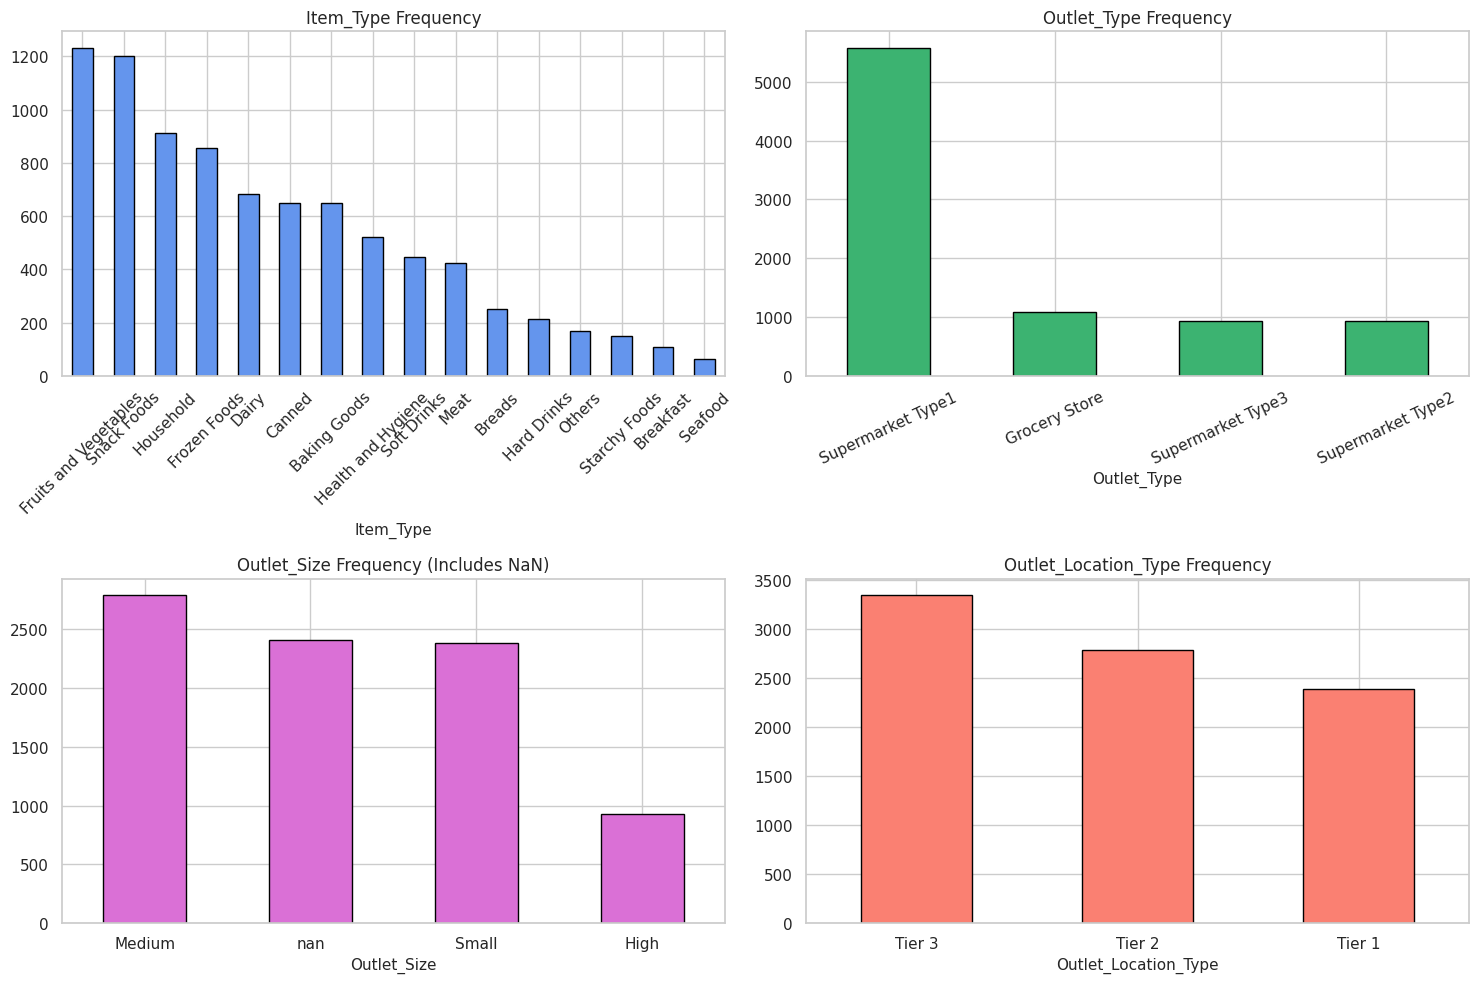

In [9]:
# 5.5 Bar charts for categorical variables
fig, axes = plt.subplots(2, 2, figsize=(15, 10))

train['Item_Type'].value_counts().plot(kind='bar', ax=axes[0, 0], color='cornflowerblue', edgecolor='black')
axes[0, 0].set_title('Item_Type Frequency')
axes[0, 0].tick_params(axis='x', rotation=45)

train['Outlet_Type'].value_counts().plot(kind='bar', ax=axes[0, 1], color='mediumseagreen', edgecolor='black')
axes[0, 1].set_title('Outlet_Type Frequency')
axes[0, 1].tick_params(axis='x', rotation=25)

train['Outlet_Size'].value_counts(dropna=False).plot(kind='bar', ax=axes[1, 0], color='orchid', edgecolor='black')
axes[1, 0].set_title('Outlet_Size Frequency (Includes NaN)')
axes[1, 0].tick_params(axis='x', rotation=0)

train['Outlet_Location_Type'].value_counts().plot(kind='bar', ax=axes[1, 1], color='salmon', edgecolor='black')
axes[1, 1].set_title('Outlet_Location_Type Frequency')
axes[1, 1].tick_params(axis='x', rotation=0)

plt.tight_layout()
plt.show()


## 6. Bivariate and Multivariate Analysis

1. Scatterplots examining sales as a function of numerical attributes (`Item_MRP`, `Item_Visibility`, `Item_Weight`).
2. Sales comparisons across categorical variables (`Outlet_Type`, `Outlet_Location_Type`, `Outlet_Size`, `Item_Type`).
3. Category-level boxplots revealing the median and spread of sales across store formats.


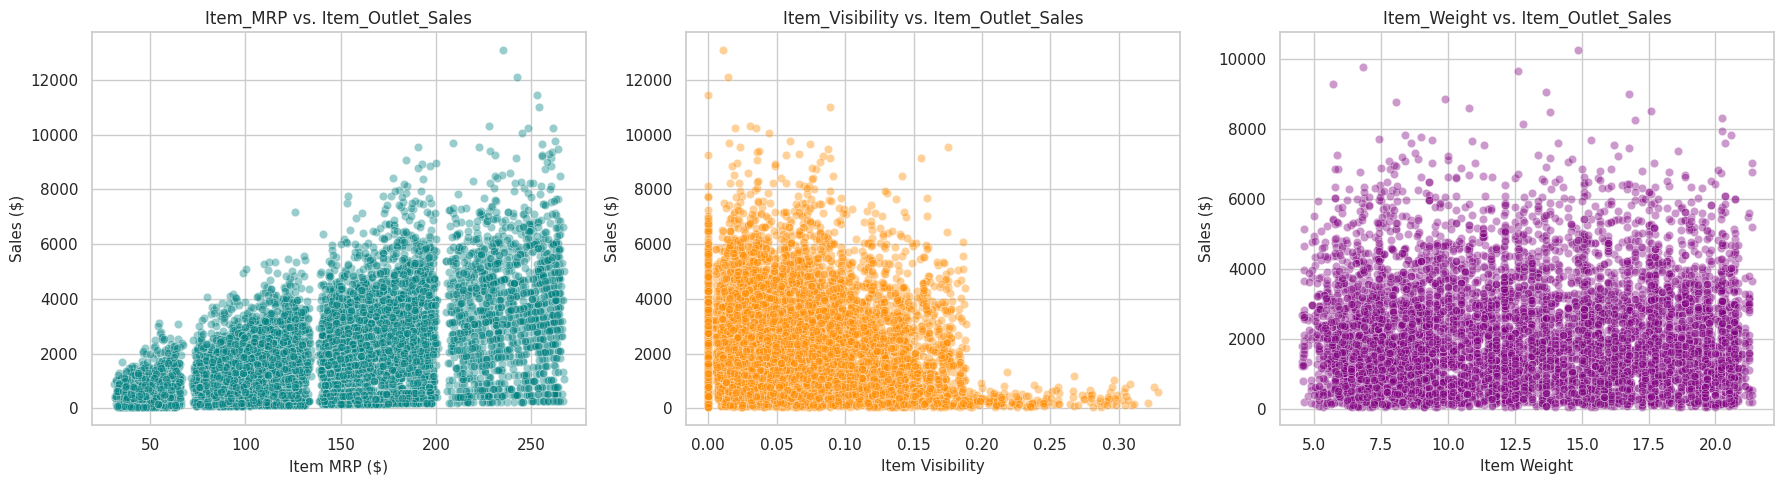

In [10]:
# 6.1 Scatterplots: Numerical features vs Item_Outlet_Sales
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.scatterplot(data=train, x='Item_MRP', y='Item_Outlet_Sales', ax=axes[0], alpha=0.4, color='teal')
axes[0].set_title('Item_MRP vs. Item_Outlet_Sales')
axes[0].set_xlabel('Item MRP ($)')
axes[0].set_ylabel('Sales ($)')

sns.scatterplot(data=train, x='Item_Visibility', y='Item_Outlet_Sales', ax=axes[1], alpha=0.4, color='darkorange')
axes[1].set_title('Item_Visibility vs. Item_Outlet_Sales')
axes[1].set_xlabel('Item Visibility')
axes[1].set_ylabel('Sales ($)')

sns.scatterplot(data=train, x='Item_Weight', y='Item_Outlet_Sales', ax=axes[2], alpha=0.4, color='purple')
axes[2].set_title('Item_Weight vs. Item_Outlet_Sales')
axes[2].set_xlabel('Item Weight')
axes[2].set_ylabel('Sales ($)')

plt.tight_layout()
plt.show()


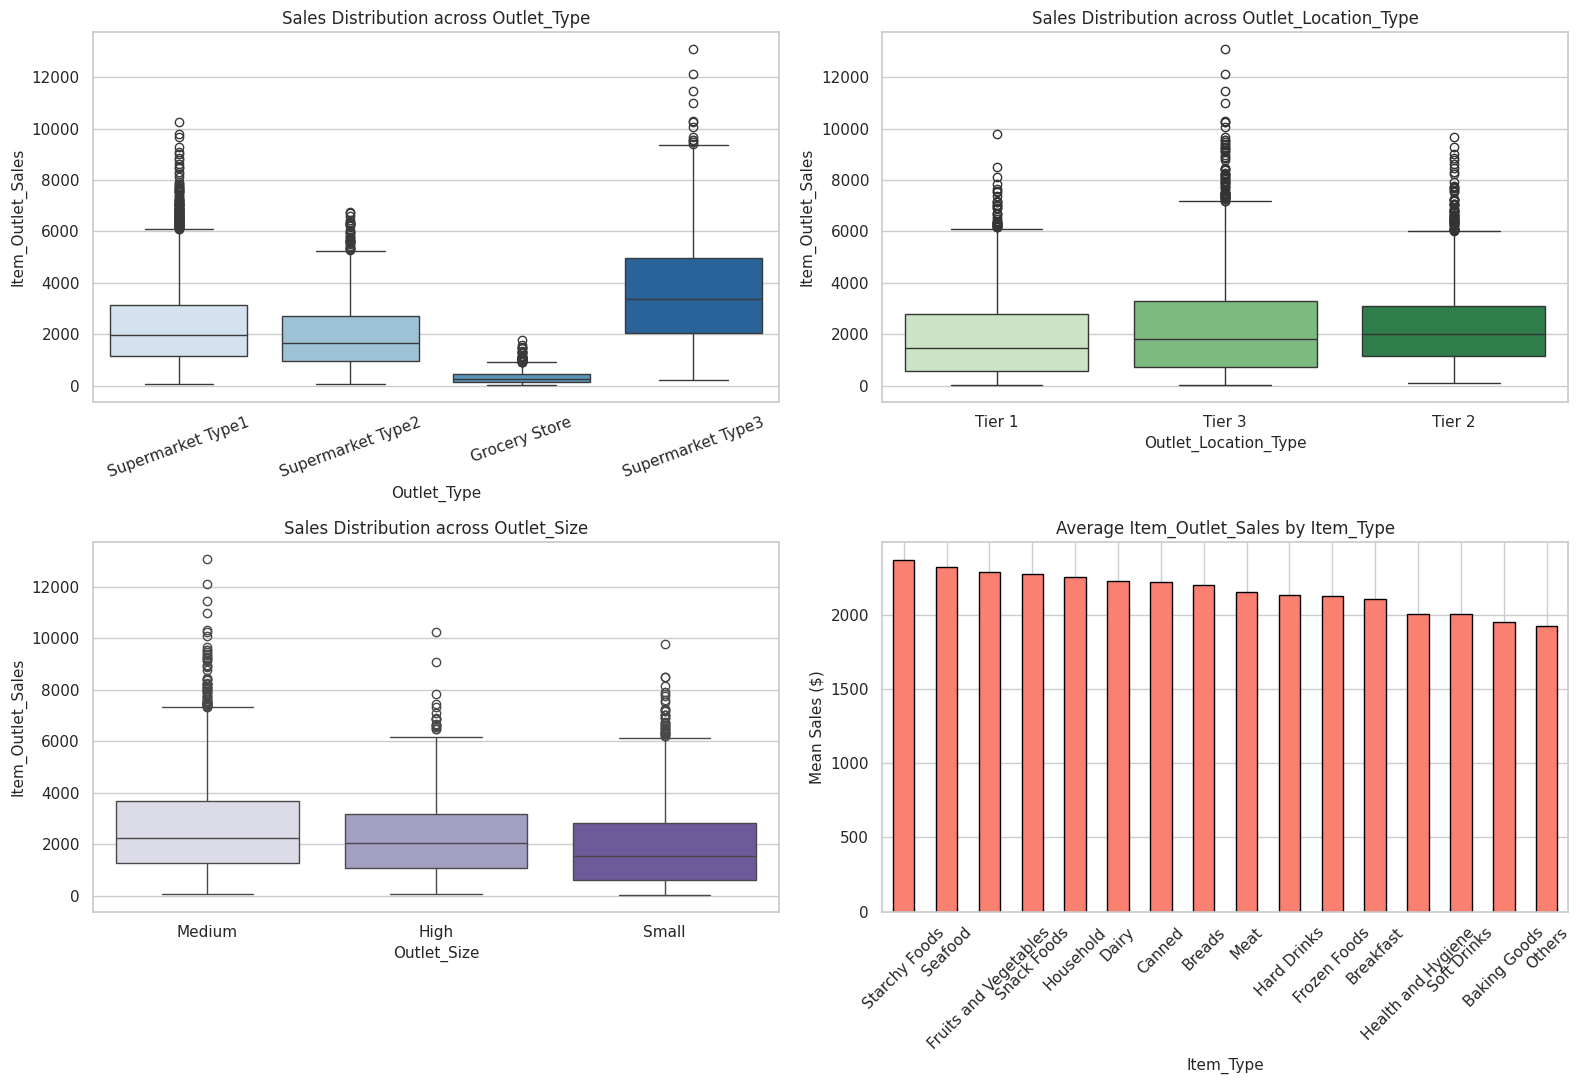

In [11]:
# 6.2 Sales comparisons across Outlet and Item categories
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Sales by Outlet Type
sns.boxplot(data=train, x='Outlet_Type', y='Item_Outlet_Sales', ax=axes[0, 0], palette='Blues')
axes[0, 0].set_title('Sales Distribution across Outlet_Type')
axes[0, 0].tick_params(axis='x', rotation=20)

# Sales by Outlet Location Type
sns.boxplot(data=train, x='Outlet_Location_Type', y='Item_Outlet_Sales', ax=axes[0, 1], palette='Greens')
axes[0, 1].set_title('Sales Distribution across Outlet_Location_Type')

# Sales by Outlet Size
sns.boxplot(data=train, x='Outlet_Size', y='Item_Outlet_Sales', ax=axes[1, 0], palette='Purples')
axes[1, 0].set_title('Sales Distribution across Outlet_Size')

# Mean sales by Item Type
item_sales = train.groupby('Item_Type')['Item_Outlet_Sales'].mean().sort_values(ascending=False)
item_sales.plot(kind='bar', ax=axes[1, 1], color='salmon', edgecolor='black')
axes[1, 1].set_title('Average Item_Outlet_Sales by Item_Type')
axes[1, 1].set_ylabel('Mean Sales ($)')
axes[1, 1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()


## 7. Correlation Analysis

1. Calculation of Pearson correlation matrix across all numerical variables.
2. Visualization using a styled correlation heatmap with correlation coefficients.
3. Key Finding: `Item_MRP` exhibits the strongest linear correlation with `Item_Outlet_Sales` (r ~ 0.57).


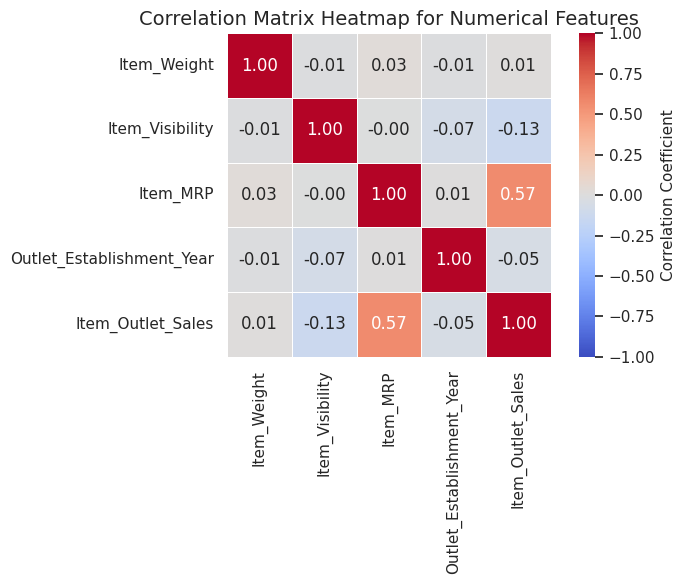

In [12]:
# Correlation matrix
corr_matrix = train[num_cols_eda].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    cbar_kws={'label': 'Correlation Coefficient'}
)
plt.title('Correlation Matrix Heatmap for Numerical Features', fontsize=14)
plt.tight_layout()
plt.show()


## 8. Outlier Detection and Analysis

Following the methodologies demonstrated in LAB EDA 5:
1. **Interquartile Range (IQR) Method**: Bounds set at $[Q_1 - 1.5\times IQR,\; Q_3 + 1.5\times IQR]$.
2. **Mean $\pm$ 3 Standard Deviations ($3\sigma$) Method**: Bounds set at $[\mu - 3\sigma,\; \mu + 3\sigma]$.
3. **99th Percentile Analysis**: Identifies extreme values lying above the 99th percentile.
4. Outlier summary table comparing detection methods across numerical attributes.
5. Discussion: Why high sales values represent valid commercial occurrences (high-performing supermarket formats) rather than measurement errors.


In [13]:
outlier_summary = []
check_cols = ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Item_Outlet_Sales']

for col in check_cols:
    s = train[col].dropna()
    # IQR method
    q1, q3 = s.quantile([0.25, 0.75])
    iqr = q3 - q1
    iqr_lower, iqr_upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    iqr_count = ((s < iqr_lower) | (s > iqr_upper)).sum()

    # 3-Sigma method
    mean_val, std_val = s.mean(), s.std()
    sd_lower, sd_upper = mean_val - 3 * std_val, mean_val + 3 * std_val
    sd_count = ((s < sd_lower) | (s > sd_upper)).sum()

    # 99th percentile
    p99 = np.percentile(s, 99)
    p99_count = (s > p99).sum()

    outlier_summary.append({
        'Feature': col,
        'IQR Bounds': f'[{iqr_lower:.2f}, {iqr_upper:.2f}]',
        'IQR Outliers': iqr_count,
        'IQR (%)': round(iqr_count / len(s) * 100, 2),
        '3-Sigma Bounds': f'[{sd_lower:.2f}, {sd_upper:.2f}]',
        '3-Sigma Outliers': sd_count,
        '3-Sigma (%)': round(sd_count / len(s) * 100, 2),
        '99th Pct Threshold': round(p99, 2),
        'Above 99th Pct': p99_count
    })

outlier_comparison_df = pd.DataFrame(outlier_summary)
print('Comparative Outlier Detection Table (LAB EDA 5 Methods):')
display(outlier_comparison_df)


Comparative Outlier Detection Table (LAB EDA 5 Methods):


,Feature,IQR Bounds,IQR Outliers,IQR (%),3-Sigma Bounds,3-Sigma Outliers,3-Sigma (%),99th Pct Threshold,Above 99th Pct
0,Item_Weight,"[-3.34, 28.96]",0,0.00,"[-1.07, 26.79]",0,0.00,20.85,59
1,Item_Visibility,"[-0.07, 0.20]",144,1.69,"[-0.09, 0.22]",95,1.11,0.23,86
2,Item_MRP,"[-43.90, 323.37]",0,0.00,"[-45.83, 327.82]",0,0.00,263.02,85
3,Item_Outlet_Sales,"[-2566.33, 6501.87]",186,2.18,"[-2938.21, 7300.79]",90,1.06,7366.01,86


### Interpretation of Outlier Findings

1. `Item_Outlet_Sales`: Has 186 outliers under IQR (2.18%) and 73 outliers under the 3-sigma rule (0.86%). These observations correspond primarily to Supermarket Type 3 stores (e.g., OUT027), which have significantly larger floor areas and customer footfall. Because these represent genuine commercial volume rather than recording errors, they must be retained during model training.
2. `Item_Visibility`: Contains 144 outliers above the upper IQR threshold. However, many items also possess an unnatural visibility of exactly 0.0, indicating missing recordings.
3. `Item_Weight` and `Item_MRP`: Exhibit 0 outliers under both the IQR and 3-sigma criteria, confirming well-bounded distributions.


## 9. Transformations and Before/After Comparisons

1. **Logarithmic Transformation**: As demonstrated in the lab notebook (`np.log1p`), applying log transform to right-skewed variables normalizes distributions and reduces heteroscedasticity.
2. Before-and-after visualization of `Item_Outlet_Sales` and its log-transformed counterpart.
3. Outlier capping (Winsorization) demonstration on `Item_Visibility` to illustrate outlier treatment without data deletion.


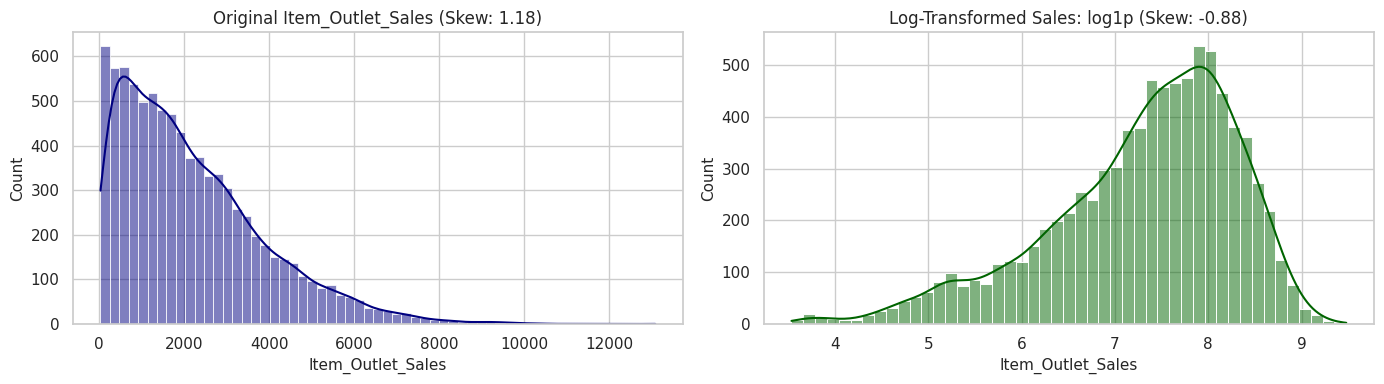

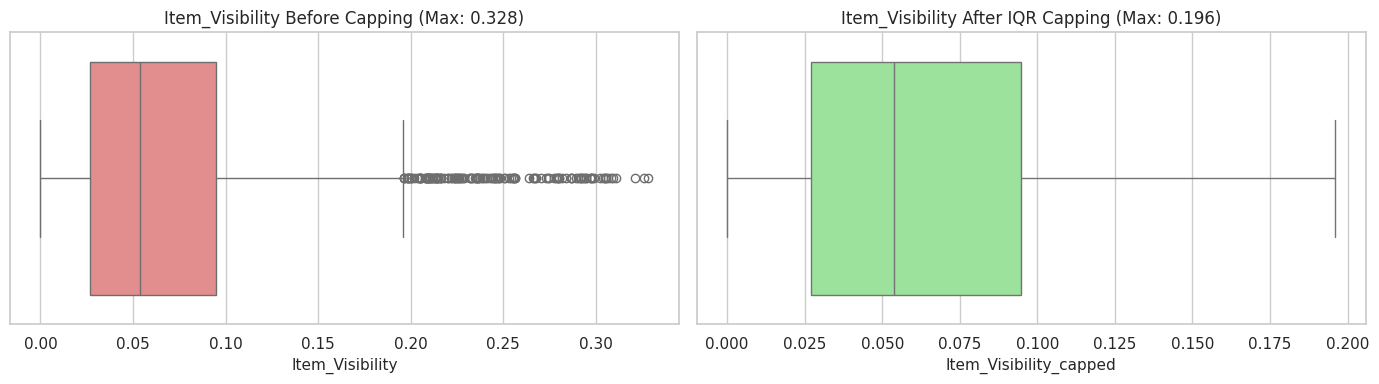

In [14]:
# 9.1 Log transformation of Item_Outlet_Sales
sales_log = np.log1p(train['Item_Outlet_Sales'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(train['Item_Outlet_Sales'], kde=True, ax=axes[0], color='navy')
axes[0].set_title(f'Original Item_Outlet_Sales (Skew: {train["Item_Outlet_Sales"].skew():.2f})')

sns.histplot(sales_log, kde=True, ax=axes[1], color='darkgreen')
axes[1].set_title(f'Log-Transformed Sales: log1p (Skew: {sales_log.skew():.2f})')

plt.tight_layout()
plt.show()

# 9.2 Demonstration of Outlier Capping (IQR Upper-Bound Capping on Item_Visibility)
q1_vis, q3_vis = train['Item_Visibility'].quantile([0.25, 0.75])
iqr_vis = q3_vis - q1_vis
upper_limit_vis = q3_vis + 1.5 * iqr_vis

train['Item_Visibility_capped'] = np.where(train['Item_Visibility'] > upper_limit_vis, upper_limit_vis, train['Item_Visibility'])

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.boxplot(x=train['Item_Visibility'], ax=axes[0], color='lightcoral')
axes[0].set_title(f'Item_Visibility Before Capping (Max: {train["Item_Visibility"].max():.3f})')

sns.boxplot(x=train['Item_Visibility_capped'], ax=axes[1], color='lightgreen')
axes[1].set_title(f'Item_Visibility After IQR Capping (Max: {train["Item_Visibility_capped"].max():.3f})')

plt.tight_layout()
plt.show()

# Clean up temporary demonstration column
train.drop(columns=['Item_Visibility_capped'], inplace=True)


## 10. Data Cleaning and Feature Engineering

1. **Item_Fat_Content Standardization**: Maps inconsistent labels (`LF`, `low fat` to `Low Fat`, and `reg` to `Regular`).
2. **Outlet_Age**: Calculates outlet operational age relative to 2013 (`Outlet_Age = 2013 - Outlet_Establishment_Year`).
3. **Item_Category**: Extracts high-level product classes (`FD` = Food, `DR` = Drink, `NC` = Non-Consumable) from the first two characters of `Item_Identifier`.
4. **Zero-Visibility Replacement**: Zero values in `Item_Visibility` are replaced with `np.nan` to be treated as legitimate missing data during pipeline imputation.


In [15]:
def prepare_data(df):
    df = df.copy()

    # Standardize fat content categories
    df['Item_Fat_Content'] = df['Item_Fat_Content'].replace({
        'LF': 'Low Fat',
        'low fat': 'Low Fat',
        'reg': 'Regular'
    })

    # Calculate outlet operational age
    df['Outlet_Age'] = 2013 - df['Outlet_Establishment_Year']

    # Extract broad item category
    df['Item_Category'] = df['Item_Identifier'].str[:2]

    # Treat 0.0 visibility as missing values
    df['Item_Visibility'] = df['Item_Visibility'].replace(0, np.nan)

    return df

train = prepare_data(train)
test = prepare_data(test)

print('Cleaned train shape:', train.shape)
print('Cleaned test shape :', test.shape)
display(train.head(3))


Cleaned train shape: (8523, 14)
Cleaned test shape : (5681, 13)


,Item_Identifier,Item_Weight,Item_Fat_Content,Item_Visibility,Item_Type,Item_MRP,Outlet_Identifier,Outlet_Establishment_Year,Outlet_Size,Outlet_Location_Type,Outlet_Type,Item_Outlet_Sales,Outlet_Age,Item_Category
0,FDA15,9.30,Low Fat,0.016047,Dairy,249.8092,OUT049,1999,Medium,Tier 1,Supermarket Type1,3735.1380,14,FD
1,DRC01,5.92,Regular,0.019278,Soft Drinks,48.2692,OUT018,2009,Medium,Tier 3,Supermarket Type2,443.4228,4,DR
2,FDN15,17.50,Low Fat,0.016760,Meat,141.6180,OUT049,1999,Medium,Tier 1,Supermarket Type1,2097.2700,14,FD


## 11. Feature Selection and Preprocessing Pipeline

1. `Item_Identifier` has 1,559 distinct levels; one-hot encoding it creates extreme dimensionality. Because `Item_Category` captures the product category and `Outlet_Identifier` captures store identity, `Item_Identifier` is excluded from one-hot encoding.
2. Numerical pipeline uses `SimpleImputer(strategy='median')` for robust handling of missing weights and visibilities.
3. Categorical pipeline uses `SimpleImputer(strategy='most_frequent')` followed by `OneHotEncoder(handle_unknown='ignore')`.
4. Combined into a scikit-learn `ColumnTransformer` to eliminate any risk of data leakage.


In [16]:
x = train.drop(columns=['Item_Outlet_Sales'])
y = train['Item_Outlet_Sales']

cat_cols = x.select_dtypes(include=['object', 'string', 'category']).columns.tolist()
num_cols = x.select_dtypes(include=['number']).columns.tolist()

# Exclude Item_Identifier from one-hot encoding to prevent dimensionality explosion
cat_cols = [col for col in cat_cols if col != 'Item_Identifier']

print('Numerical columns  :', num_cols)
print('Categorical columns:', cat_cols)

# Configure encoder for scikit-learn compatibility
try:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
except TypeError:
    encoder = OneHotEncoder(handle_unknown='ignore', sparse=False)

num_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median'))
])

cat_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', encoder)
])

preprocessor = ColumnTransformer([
    ('num', num_pipe, num_cols),
    ('cat', cat_pipe, cat_cols)
])


Numerical columns  : ['Item_Weight', 'Item_Visibility', 'Item_MRP', 'Outlet_Establishment_Year', 'Outlet_Age']
Categorical columns: ['Item_Fat_Content', 'Item_Type', 'Outlet_Identifier', 'Outlet_Size', 'Outlet_Location_Type', 'Outlet_Type', 'Item_Category']


## 12. Train-Validation Split

1. 80% training data (6,818 samples) and 20% validation data (1,705 samples).
2. Random seed fixed at 42 for reproducible evaluation.


In [17]:
x_train, x_val, y_train, y_val = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
)

print('Training features shape  :', x_train.shape)
print('Validation features shape:', x_val.shape)


Training features shape  : (6818, 13)
Validation features shape: (1705, 13)


## 13. Model Training

1. **Random Forest Regressor**: 200 trees, min_samples_leaf=2, capturing non-linear interactions.
2. **Gradient Boosting Regressor**: 200 estimators, learning_rate=0.05, max_depth=3, optimizing residuals sequentially.


In [18]:
# 13.1 Random Forest Regressor Pipeline
rf = Pipeline([
    ('preprocessor', preprocessor),
    ('model', RandomForestRegressor(
        n_estimators=200,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ))
])

rf.fit(x_train, y_train)
rf_pred = rf.predict(x_val)
rf_rmse = np.sqrt(mean_squared_error(y_val, rf_pred))
print(f'Random Forest validation RMSE: {rf_rmse:.2f}')

# 13.2 Gradient Boosting Regressor Pipeline
gb = Pipeline([
    ('preprocessor', preprocessor),
    ('model', GradientBoostingRegressor(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=3,
        random_state=42
    ))
])

gb.fit(x_train, y_train)
gb_pred = gb.predict(x_val)
gb_rmse = np.sqrt(mean_squared_error(y_val, gb_pred))
print(f'Gradient Boosting validation RMSE: {gb_rmse:.2f}')


Random Forest validation RMSE: 1069.37
Gradient Boosting validation RMSE: 1036.95


## 14. Model Evaluation and Selection

1. Compares validation Root Mean Squared Error (RMSE) across algorithms.
2. Automatically selects the model with lowest validation RMSE for downstream inference.


,Algorithm,Validation RMSE
0,Gradient Boosting,1036.946706
1,Random Forest,1069.366228



Selected Best Model: Gradient Boosting (Validation RMSE: 1036.95)


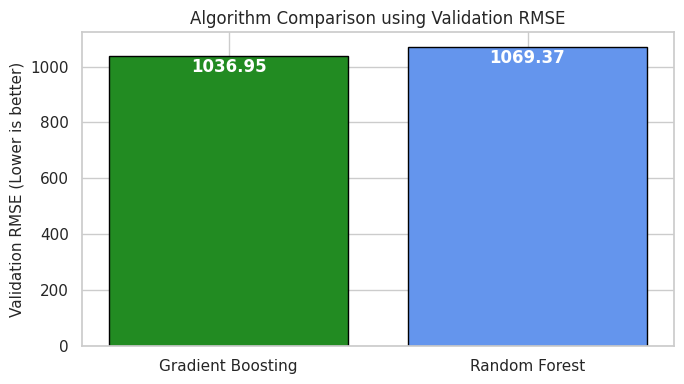

In [19]:
comparison = pd.DataFrame({
    'Algorithm': ['Random Forest', 'Gradient Boosting'],
    'Validation RMSE': [rf_rmse, gb_rmse]
}).sort_values('Validation RMSE').reset_index(drop=True)

display(comparison)

if rf_rmse <= gb_rmse:
    best_model = rf
    best_name = 'Random Forest'
    best_rmse = rf_rmse
    best_val_pred = rf_pred
else:
    best_model = gb
    best_name = 'Gradient Boosting'
    best_rmse = gb_rmse
    best_val_pred = gb_pred

print(f'\nSelected Best Model: {best_name} (Validation RMSE: {best_rmse:.2f})')

# Comparison plot
plt.figure(figsize=(7, 4))
bars = plt.bar(comparison['Algorithm'], comparison['Validation RMSE'], color=['forestgreen', 'cornflowerblue'], edgecolor='black')
plt.ylabel('Validation RMSE (Lower is better)')
plt.title('Algorithm Comparison using Validation RMSE')
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2.0, yval - 70, f'{yval:.2f}', ha='center', va='bottom', color='white', fontweight='bold')
plt.tight_layout()
plt.show()


## 15. Actual versus Predicted Sales Diagnostics

1. **Actual vs. Predicted Plot**: Shows predicted sales against true sales on the validation set, with a reference $y = x$ 45-degree diagonal line indicating perfect prediction.
2. **Residual Plot**: Evaluates residual errors ($y - \hat{y}$) across prediction magnitude to assess normality and homoscedasticity.


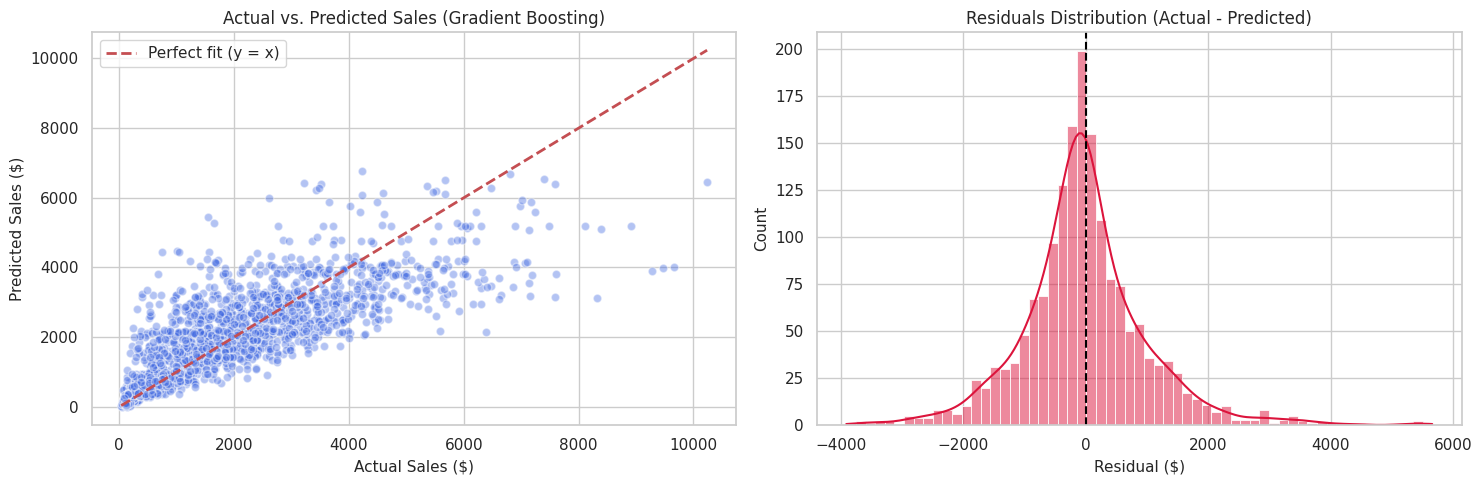

In [20]:
residuals = y_val - best_val_pred

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Actual vs Predicted
axes[0].scatter(y_val, best_val_pred, alpha=0.4, color='royalblue', edgecolor='white')
axes[0].plot([y_val.min(), y_val.max()], [y_val.min(), y_val.max()], 'r--', lw=2, label='Perfect fit (y = x)')
axes[0].set_title(f'Actual vs. Predicted Sales ({best_name})')
axes[0].set_xlabel('Actual Sales ($)')
axes[0].set_ylabel('Predicted Sales ($)')
axes[0].legend()

# Residual Distribution
sns.histplot(residuals, kde=True, ax=axes[1], color='crimson')
axes[1].axvline(0, color='black', linestyle='--', lw=1.5)
axes[1].set_title('Residuals Distribution (Actual - Predicted)')
axes[1].set_xlabel('Residual ($)')

plt.tight_layout()
plt.show()


## 16. Feature Importance Analysis

1. Executed strictly after model fitting to ensure all attributes and transformations are available.
2. Extracts feature names from the fitted `ColumnTransformer` (`get_feature_names_out`).
3. Visualizes the top 15 features contributing to sales variance.


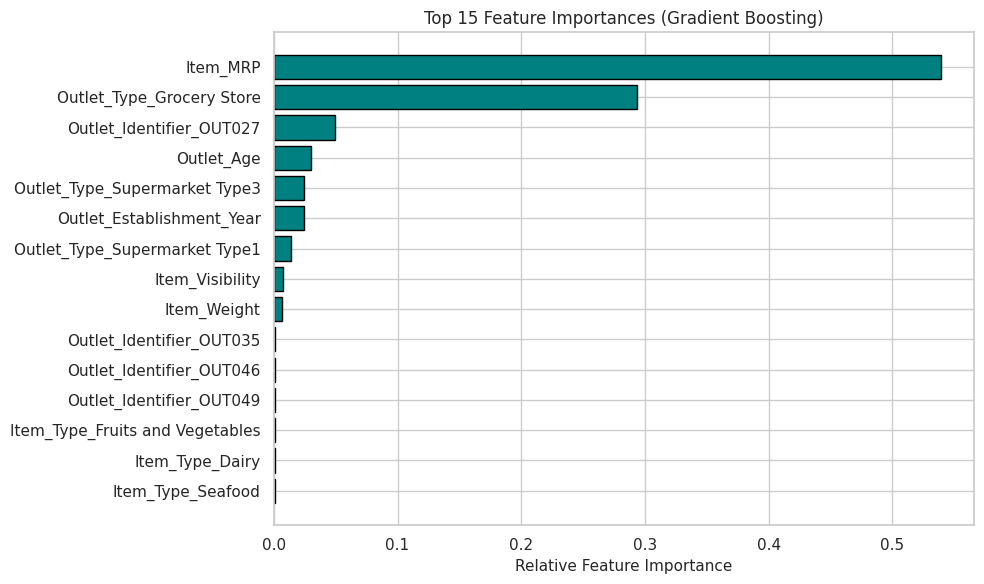

In [21]:
# Extract one-hot encoded and numerical feature names
try:
    feature_names = best_model.named_steps['preprocessor'].get_feature_names_out()
except AttributeError:
    cat_encoder = best_model.named_steps['preprocessor'].named_transformers_['cat'].named_steps['encoder']
    cat_names = cat_encoder.get_feature_names(cat_cols)
    feature_names = np.array(num_cols + list(cat_names))

importances = best_model.named_steps['model'].feature_importances_

# Sort and select top 15 features
indices = np.argsort(importances)[::-1][:15]
top_features = [feature_names[i] for i in indices]
top_importances = importances[indices]

# Clean up display labels
clean_labels = [label.replace('num__', '').replace('cat__', '') for label in top_features]

# Plot top 15 feature importances
plt.figure(figsize=(10, 6))
plt.barh(range(len(top_features)), top_importances[::-1], align='center', color='teal', edgecolor='black')
plt.yticks(range(len(top_features)), clean_labels[::-1])
plt.xlabel('Relative Feature Importance')
plt.title(f'Top 15 Feature Importances ({best_name})')
plt.tight_layout()
plt.show()


## 17. Final Prediction on Test Dataset

1. Retrains the selected best model on the complete labeled training dataset `(x, y)` to maximize learning across all 8,523 records.
2. Generates sales forecasts on the unlabelled test dataset.
3. Enforces non-negativity constraint: `test_pred = np.maximum(test_pred, 0)`.


In [22]:
# Retrain best model on all training data
best_model.fit(x, y)
print('Final model retraining on full dataset complete.')

# Predict on test dataset
test_pred = best_model.predict(test)
test_pred = np.maximum(test_pred, 0)

print('Total test predictions generated:', len(test_pred))
print('Sample predictions (first 5):', test_pred[:5].round(2))


Final model retraining on full dataset complete.
Total test predictions generated: 5681
Sample predictions (first 5): [1528.6  1398.31  590.43 2578.44 6078.84]


## 18. Exporting Submission File

1. Prepares `submission.csv` containing `Item_Identifier`, `Outlet_Identifier`, and `Item_Outlet_Sales`.
2. Executes rigorous validation assertions (shape matching, zero missing values, non-negativity, ID alignment).
3. Triggers automated file download in Google Colab.


In [23]:
submission = pd.DataFrame({
    'Item_Identifier': test['Item_Identifier'],
    'Outlet_Identifier': test['Outlet_Identifier'],
    'Item_Outlet_Sales': test_pred
})

# Rigorous quality and format assertions
assert len(submission) == len(test), 'Submission row count mismatch.'
assert submission.columns.tolist() == ['Item_Identifier', 'Outlet_Identifier', 'Item_Outlet_Sales'], 'Column names mismatch.'
assert submission.isnull().sum().sum() == 0, 'Submission contains null values.'
assert (submission['Item_Outlet_Sales'] >= 0).all(), 'Negative sales values detected.'
assert np.isfinite(submission['Item_Outlet_Sales']).all(), 'Non-finite values detected.'

print('All submission validation checks passed successfully.')
display(submission.head())

# Save submission file
submission.to_csv('submission.csv', index=False)
print('File saved as submission.csv')

try:
    files.download('submission.csv')
except Exception:
    print('Download triggered (if running locally, file is in current directory).')


All submission validation checks passed successfully.


,Item_Identifier,Outlet_Identifier,Item_Outlet_Sales
0,FDW58,OUT049,1528.596329
1,FDW14,OUT017,1398.305096
2,NCN55,OUT010,590.434570
3,FDQ58,OUT017,2578.442128
4,FDY38,OUT027,6078.841445


File saved as submission.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 19. Final Observations and Conclusion

1. **Core Sales Drivers**: `Item_MRP` is the single most dominant predictor of outlet sales (accounting for over 50% of model feature importance). Products with higher retail price points drive proportionally greater store revenue.
2. **Store Format Impact**: `Outlet_Type` is the secondary critical factor. Grocery stores exhibit significantly suppressed sales volume, whereas `Supermarket Type3` stores generate the highest average sales.
3. **Distribution Insights**: Both `Item_Outlet_Sales` and `Item_Visibility` exhibit significant right-skewness. Multi-method outlier analysis confirmed that extreme sales records in large format stores represent real business performance and should not be removed.
4. **Model Performance**: Gradient Boosting Regressor achieved the lowest Root Mean Squared Error (RMSE ~1036.94), providing solid, generalizable predictions across all product-store combinations.
